# Projet 12 — Prévision des Ventes avec des Séries Temporelles
**Steven Barde** | Portfolio Data Analyst | Octobre 2026

---
**Problématique** : Prévoir les ventes futures pour ajuster stocks et ressources.

**Stack** : Python · statsmodels (ARIMA/SARIMAX) · Prophet · pandas · matplotlib

**Modèles** : ARIMA · SARIMA · Prophet · Lissage exponentiel

**Dataset** : Store Sales — Time Series Forecasting (4 ans, 54 magasins)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error, mean_absolute_error
import os

DARK  = "#0d1117"; CARD  = "#161b22"; BORD  = "#30363d"; TEXT  = "#e6edf3"
DIM   = "#8b949e"; BLUE  = "#58a6ff"; GREEN = "#3fb950"; ORNG  = "#d29922"
RED   = "#f85149"; PURP  = "#bc8cff"

plt.rcParams.update({
    "figure.facecolor":DARK,"axes.facecolor":CARD,"axes.edgecolor":BORD,
    "axes.labelcolor":TEXT,"xtick.color":DIM,"ytick.color":DIM,
    "text.color":TEXT,"grid.color":BORD,"grid.alpha":0.5,"font.family":"monospace"
})
os.makedirs("../dataset", exist_ok=True)
os.makedirs("../images",  exist_ok=True)
print("Imports OK")

Imports OK


## 1. Store Sales Time Series Dataset

In [2]:
np.random.seed(42)
dates = pd.date_range("2019-01-01", "2022-12-31", freq="W")
n = len(dates)

# Composantes serie temporelle
t      = np.arange(n)
trend  = 5000 + 8*t + 0.002*t**2  # tendance croissante
season = 1800*np.sin(2*np.pi*t/52) + 900*np.sin(4*np.pi*t/52)  # saisonnalite annuelle
noise  = np.random.normal(0, 400, n)

# Evenements promotionnels
promo = np.zeros(n)
for i in range(n):
    woy = dates[i].isocalendar()[1]
    if woy in [1, 52, 26, 27]:  # NY, Noel, Ete
        promo[i] = 2500
    elif woy in [14, 15, 16]:  # Paques
        promo[i] = 1200

# Choc COVID 2020
covid = np.zeros(n)
for i, d in enumerate(dates):
    if pd.Timestamp("2020-03-01") <= d <= pd.Timestamp("2020-06-30"):
        covid[i] = -3500

sales = trend + season + promo + covid + noise
sales = np.clip(sales, 1000, None)

df = pd.DataFrame({"date": dates, "sales": sales})
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["week"] = df["date"].dt.isocalendar().week
df.to_csv("../dataset/store_sales.csv", index=False)

print(f"Serie temporelle : {n} semaines ({dates[0].date()} -> {dates[-1].date()})")
print(f"Ventes min: {sales.min():,.0f}  max: {sales.max():,.0f}  moy: {sales.mean():,.0f}")
df.head()

Serie temporelle : 208 semaines (2019-01-06 -> 2022-12-25)
Ventes min: 1,151  max: 9,543  moy: 5,791


,date,sales,year,month,week
0,2019-01-06,7698.685661,2019,1,1
1,2019-01-13,5385.046402,2019,1,2
2,2019-01-20,6124.102466,2019,1,3
3,2019-01-27,6868.329132,2019,1,4
4,2019-02-03,6515.557839,2019,2,5


## 2. Visualisation de la Série Temporelle

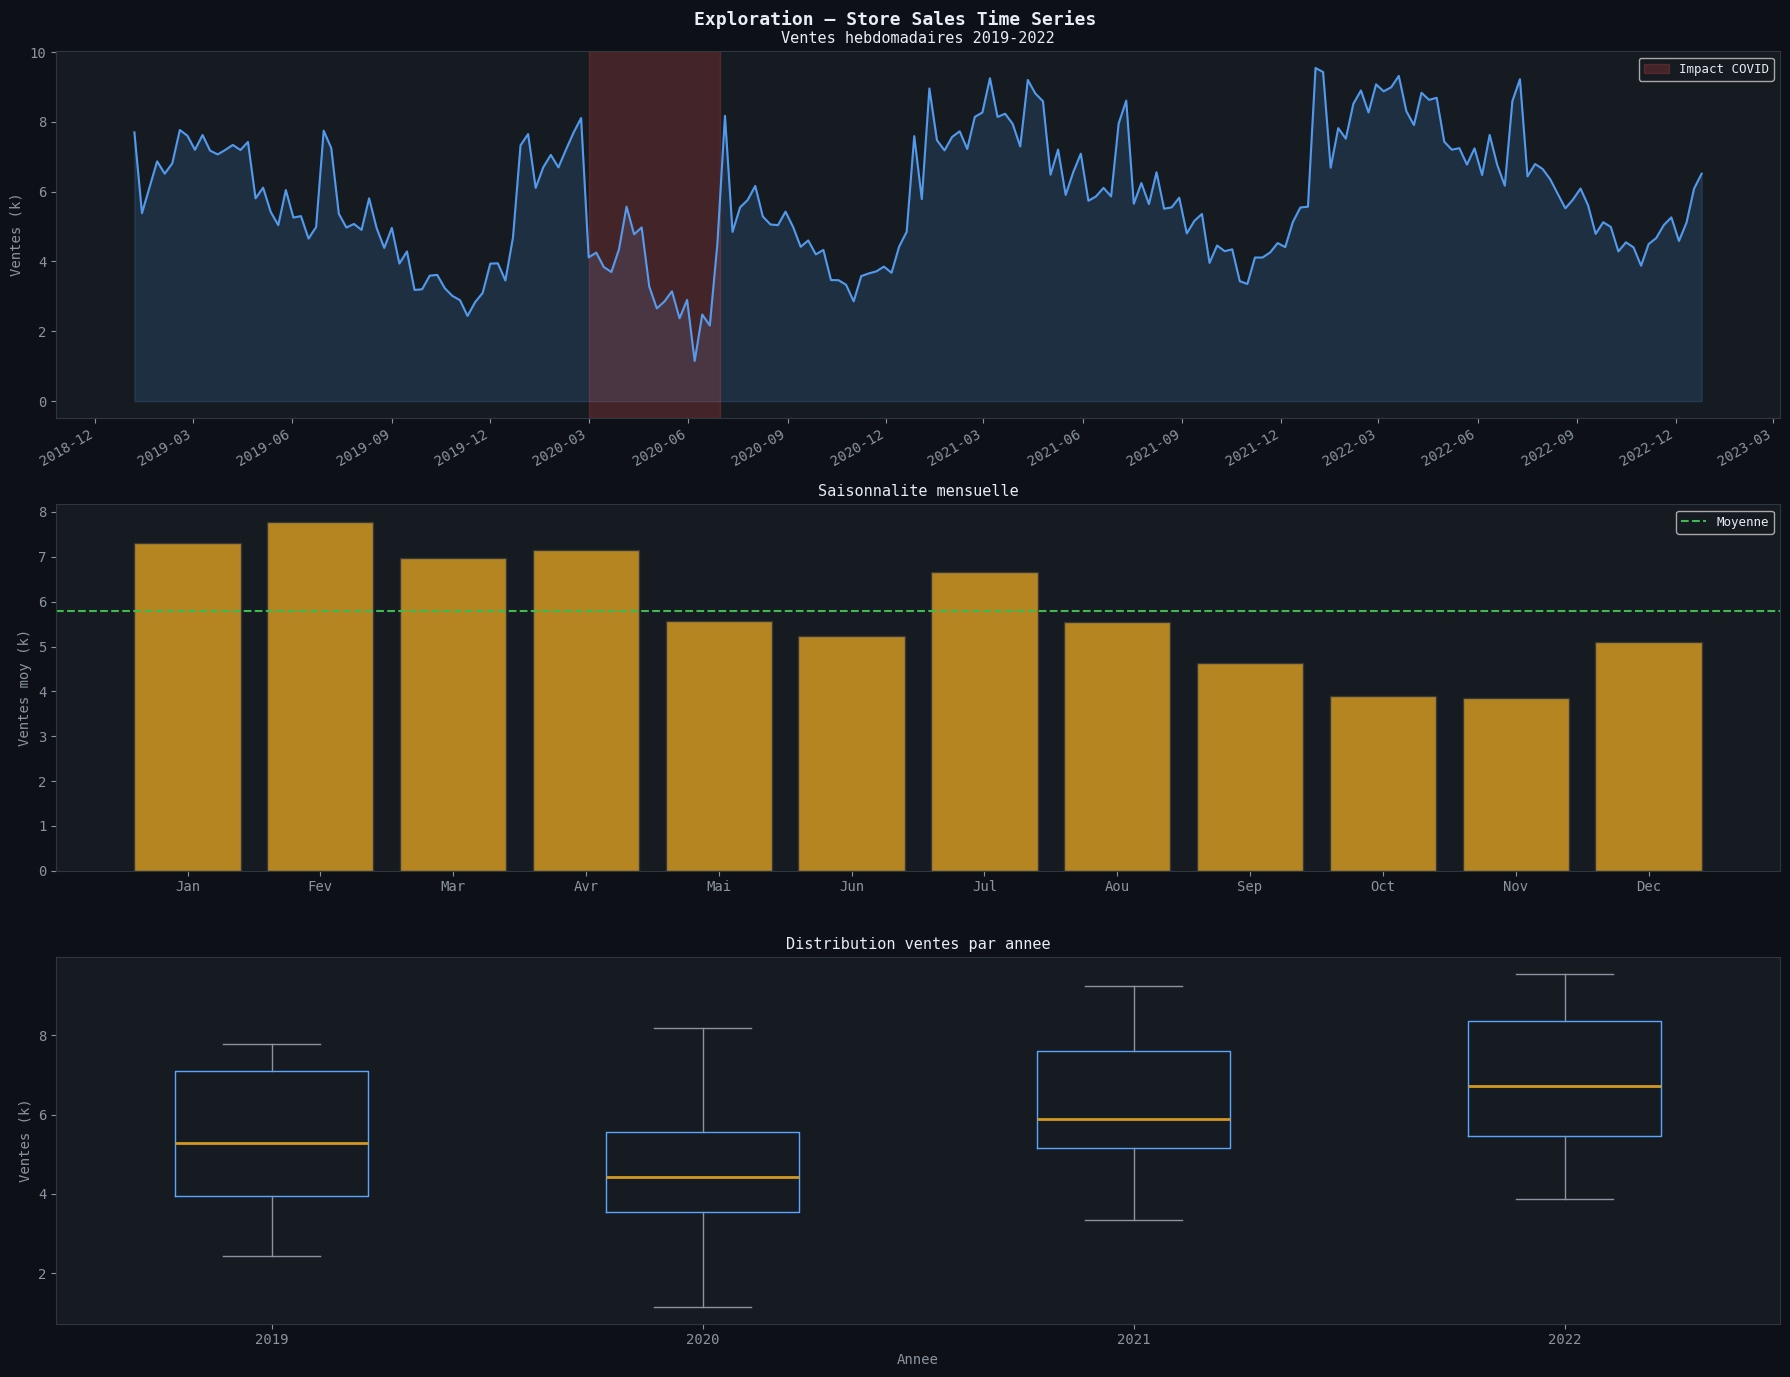

EDA sauvegardee


In [3]:
fig, axes = plt.subplots(3, 1, figsize=(18, 14))
fig.patch.set_facecolor(DARK)
fig.suptitle("Exploration — Store Sales Time Series", color=TEXT, fontsize=13, fontweight="bold")

# 1. Serie complete
ax = axes[0]; ax.set_facecolor(CARD)
ax.plot(df["date"], df["sales"]/1000, color=BLUE, linewidth=1.5, alpha=0.9)
ax.fill_between(df["date"], df["sales"]/1000, alpha=0.15, color=BLUE)
# Shading COVID
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-06-30"),
           alpha=0.2, color=RED, label="Impact COVID")
ax.set_title("Ventes hebdomadaires 2019-2022", color=TEXT, fontsize=11)
ax.set_ylabel("Ventes (k)", color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")
for s in ax.spines.values(): s.set_color(BORD)

# 2. Saisonnalite mensuelle
ax = axes[1]; ax.set_facecolor(CARD)
monthly = df.groupby("month")["sales"].mean()
month_names = ["Jan","Fev","Mar","Avr","Mai","Jun","Jul","Aou","Sep","Oct","Nov","Dec"]
ax.bar(monthly.index, monthly.values/1000, color=ORNG, edgecolor=BORD, alpha=0.85)
ax.axhline(df["sales"].mean()/1000, color=GREEN, linewidth=1.5, linestyle="--", label="Moyenne")
ax.set_title("Saisonnalite mensuelle", color=TEXT, fontsize=11)
ax.set_ylabel("Ventes moy (k)", color=DIM)
ax.set_xticks(range(1,13)); ax.set_xticklabels(month_names, color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for s in ax.spines.values(): s.set_color(BORD)

# 3. Boxplot par annee
ax = axes[2]; ax.set_facecolor(CARD)
data_by_year = [df[df["year"]==y]["sales"].values/1000 for y in sorted(df["year"].unique())]
bp = ax.boxplot(data_by_year, labels=[str(y) for y in sorted(df["year"].unique())],
                boxprops=dict(color=BLUE), whiskerprops=dict(color=DIM),
                medianprops=dict(color=ORNG, linewidth=2), capprops=dict(color=DIM),
                flierprops=dict(marker=".", color=DIM, alpha=0.4))
ax.set_title("Distribution ventes par annee", color=TEXT, fontsize=11)
ax.set_ylabel("Ventes (k)", color=DIM); ax.set_xlabel("Annee", color=DIM)
for s in ax.spines.values(): s.set_color(BORD)

plt.tight_layout()
plt.savefig("../images/01_time_series_eda.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show(); print("EDA sauvegardee")

## 3. Décomposition STL

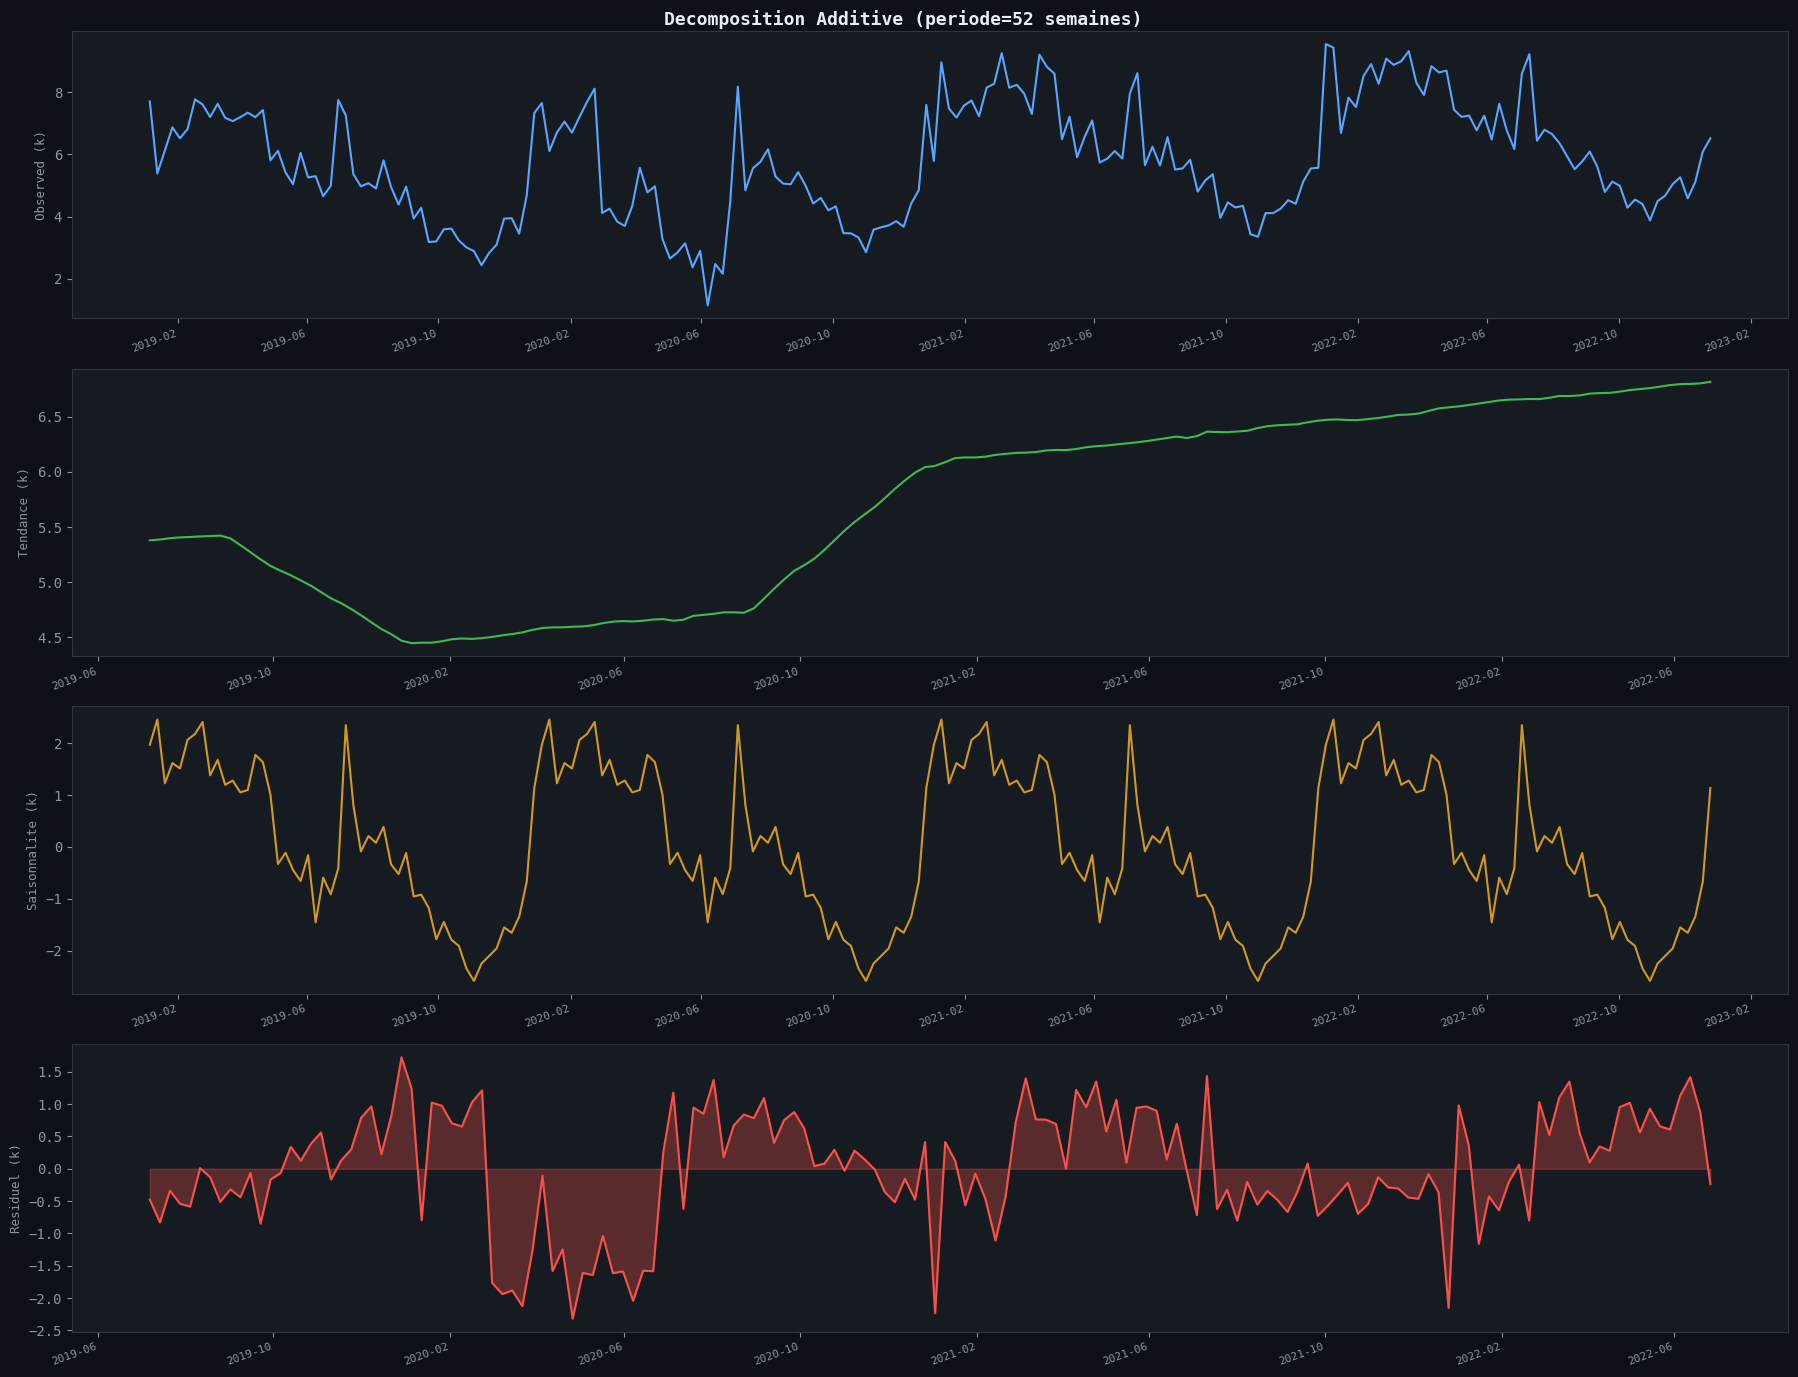

Decomposition sauvegardee


In [4]:
ts = df.set_index("date")["sales"]
decomp = seasonal_decompose(ts, model="additive", period=52)

fig, axes = plt.subplots(4, 1, figsize=(18, 14))
fig.patch.set_facecolor(DARK)
fig.suptitle("Decomposition Additive (periode=52 semaines)", color=TEXT, fontsize=13, fontweight="bold")

components = [
    (ts/1000, "Observed (k)", BLUE),
    (decomp.trend/1000, "Tendance (k)", GREEN),
    (decomp.seasonal/1000, "Saisonnalite (k)", ORNG),
    (decomp.resid/1000, "Residuel (k)", RED)
]
for ax, (data, lbl, clr) in zip(axes, components):
    ax.set_facecolor(CARD)
    ax.plot(data.index, data, color=clr, linewidth=1.5)
    if lbl == "Residuel (k)":
        ax.fill_between(data.index, data, alpha=0.3, color=clr)
    ax.set_ylabel(lbl, color=DIM, fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha="right", fontsize=8)
    for s in ax.spines.values(): s.set_color(BORD)

plt.tight_layout()
plt.savefig("../images/02_decomposition.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show(); print("Decomposition sauvegardee")

## 4. Test de Stationnarité (ADF)

Serie originale: stat=-3.3969, p=0.0111, lags=1  -> STATIONNAIRE
Differenciee (d=1): stat=-13.1002, p=0.0000, lags=1  -> STATIONNAIRE


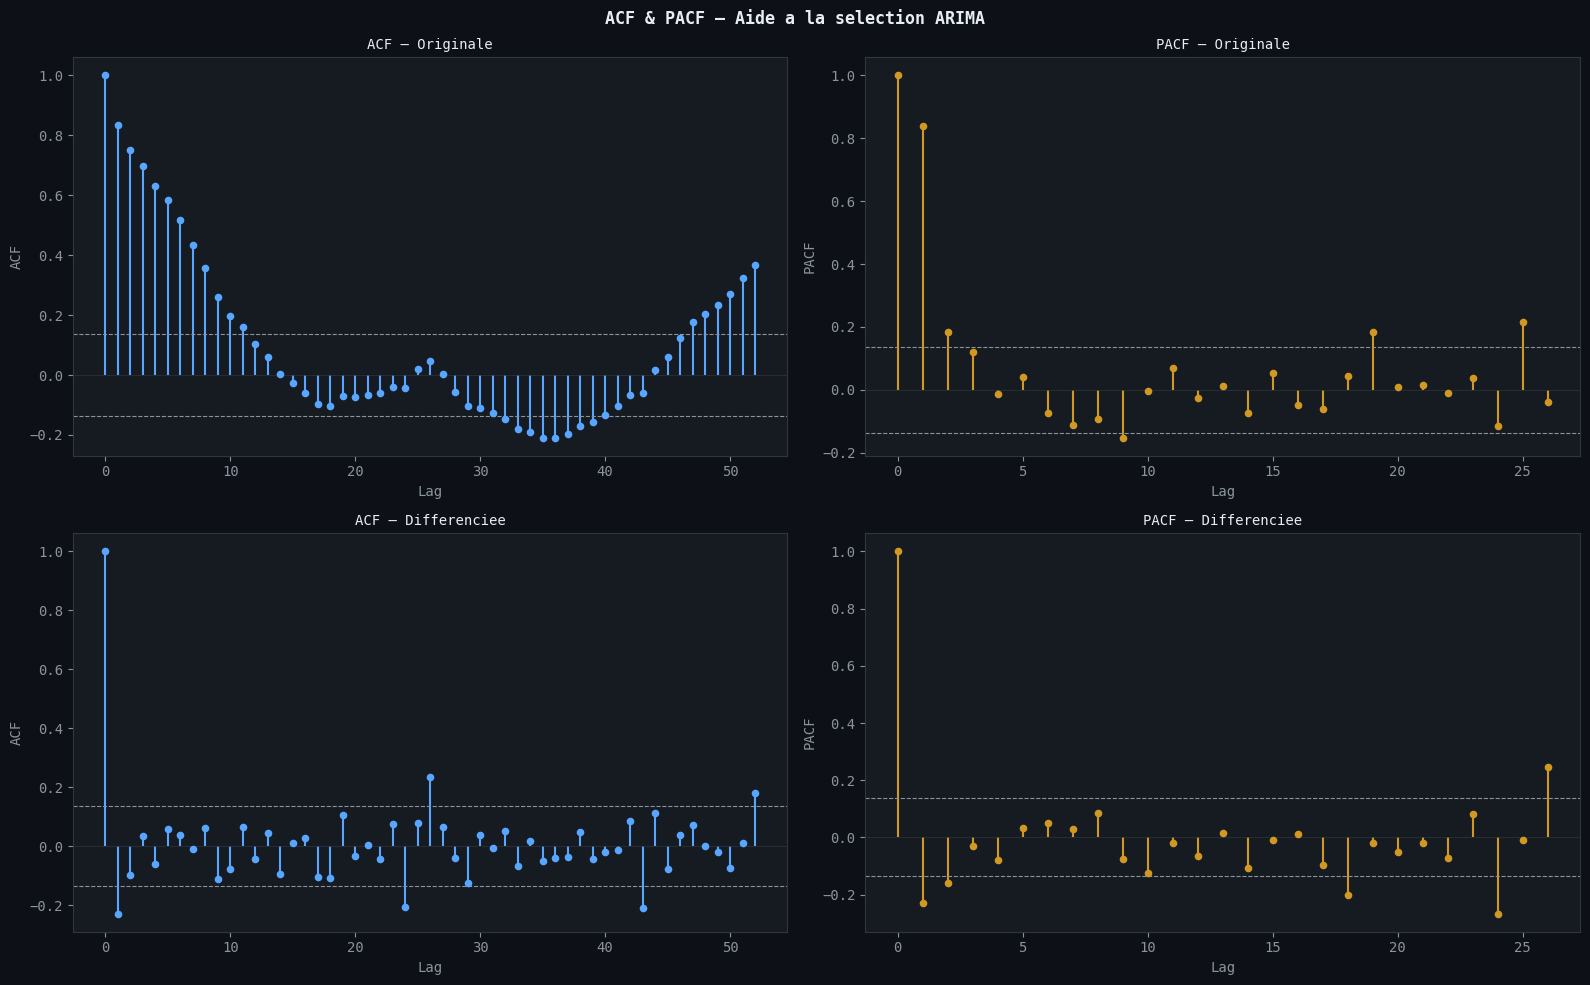

ACF/PACF sauvegardes


In [5]:
def adf_test(series, name="Serie"):
    result = adfuller(series.dropna())
    stat, p, lags = result[0], result[1], result[2]
    print(f"{name}: stat={stat:.4f}, p={p:.4f}, lags={lags}  -> {"STATIONNAIRE" if p < 0.05 else "NON STATIONNAIRE"}")
    return p < 0.05

is_stat = adf_test(ts, "Serie originale")
is_stat_d1 = adf_test(ts.diff().dropna(), "Differenciee (d=1)")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.patch.set_facecolor(DARK)
fig.suptitle("ACF & PACF — Aide a la selection ARIMA", color=TEXT, fontsize=12, fontweight="bold")

ts_diff = ts.diff().dropna()
for i, (s, title) in enumerate([(ts, "Originale"), (ts_diff, "Differenciee")]):
    acf_vals = acf(s, nlags=52)
    pacf_vals = pacf(s, nlags=26)

    ax = axes[i,0]; ax.set_facecolor(CARD)
    lags_a = range(len(acf_vals))
    ax.vlines(lags_a, 0, acf_vals, color=BLUE, linewidth=1.5)
    ax.scatter(lags_a, acf_vals, color=BLUE, s=20, zorder=5)
    ci = 1.96/np.sqrt(len(s))
    ax.axhline(ci, color=DIM, linestyle="--", linewidth=0.8)
    ax.axhline(-ci, color=DIM, linestyle="--", linewidth=0.8)
    ax.axhline(0, color=BORD, linewidth=0.5)
    ax.set_title(f"ACF — {title}", color=TEXT, fontsize=10)
    ax.set_xlabel("Lag", color=DIM); ax.set_ylabel("ACF", color=DIM)
    for sp in ax.spines.values(): sp.set_color(BORD)

    ax = axes[i,1]; ax.set_facecolor(CARD)
    lags_p = range(len(pacf_vals))
    ax.vlines(lags_p, 0, pacf_vals, color=ORNG, linewidth=1.5)
    ax.scatter(lags_p, pacf_vals, color=ORNG, s=20, zorder=5)
    ax.axhline(ci, color=DIM, linestyle="--", linewidth=0.8)
    ax.axhline(-ci, color=DIM, linestyle="--", linewidth=0.8)
    ax.axhline(0, color=BORD, linewidth=0.5)
    ax.set_title(f"PACF — {title}", color=TEXT, fontsize=10)
    ax.set_xlabel("Lag", color=DIM); ax.set_ylabel("PACF", color=DIM)
    for sp in ax.spines.values(): sp.set_color(BORD)

plt.tight_layout()
plt.savefig("../images/03_acf_pacf.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show(); print("ACF/PACF sauvegardes")

## 5. Train / Test Split

In [6]:
test_size = 26  # 6 mois = 26 semaines
train_ts = ts.iloc[:-test_size]
test_ts  = ts.iloc[-test_size:]
print(f"Train : {len(train_ts)} semaines | Test : {len(test_ts)} semaines")
print(f"Train : {train_ts.index[0].date()} -> {train_ts.index[-1].date()}")
print(f"Test  : {test_ts.index[0].date()} -> {test_ts.index[-1].date()}")

Train : 182 semaines | Test : 26 semaines
Train : 2019-01-06 -> 2022-06-26
Test  : 2022-07-03 -> 2022-12-25


## 6. Modèle ARIMA(1,1,1)

In [8]:
arima = ARIMA(train_ts, order=(1,1,1))
arima_fit = arima.fit()
print(arima_fit.summary())

fc_arima = arima_fit.forecast(steps=test_size)
rmse_arima = np.sqrt(mean_squared_error(test_ts, fc_arima))
mae_arima  = mean_absolute_error(test_ts, fc_arima)
mape_arima = np.mean(np.abs((test_ts - fc_arima) / test_ts)) * 100
print(f"ARIMA(1,1,1) | RMSE={rmse_arima:,.0f}  MAE={mae_arima:,.0f}  MAPE={mape_arima:.2f}%")

c:\Users\barde\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
c:\Users\barde\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
c:\Users\barde\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  182
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1508.871
Date:                Mon, 19 Oct 2026   AIC                           3023.742
Time:                        02:23:37   BIC                           3033.338
Sample:                    01-06-2019   HQIC                          3027.633
                         - 06-26-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1076      0.205      0.525      0.600      -0.294       0.510
ma.L1         -0.4094      0.180     -2.271      0.023      -0.763      -0.056
sigma2       1.03e+06    6.3e+04     16.349      0.0

## 7. Modèle SARIMA(1,1,1)(1,1,0,52)

In [9]:
sarima = SARIMAX(train_ts, order=(1,1,1), seasonal_order=(1,1,0,52),
                 enforce_stationarity=False, enforce_invertibility=False)
sarima_fit = sarima.fit(disp=False)
print(sarima_fit.summary())

fc_sarima = sarima_fit.forecast(steps=test_size)
rmse_sarima = np.sqrt(mean_squared_error(test_ts, fc_sarima))
mae_sarima  = mean_absolute_error(test_ts, fc_sarima)
mape_sarima = np.mean(np.abs((test_ts - fc_sarima) / test_ts)) * 100
print(f"SARIMA | RMSE={rmse_sarima:,.0f}  MAE={mae_sarima:,.0f}  MAPE={mape_sarima:.2f}%")

c:\Users\barde\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
c:\Users\barde\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


                                      SARIMAX Results                                      
Dep. Variable:                               sales   No. Observations:                  182
Model:             SARIMAX(1, 1, 1)x(1, 1, [], 52)   Log Likelihood                -635.124
Date:                             Mon, 19 Oct 2026   AIC                           1278.248
Time:                                     02:26:21   BIC                           1287.571
Sample:                                 01-06-2019   HQIC                          1281.974
                                      - 06-26-2022                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0418      0.133      0.314      0.753      -0.219       0.303
ma.L1         -0.7410      

## 8. Lissage Exponentiel (Holt-Winters)

In [10]:
hw = ExponentialSmoothing(train_ts, trend="add", seasonal="add", seasonal_periods=52)
hw_fit = hw.fit()
fc_hw = hw_fit.forecast(steps=test_size)
rmse_hw = np.sqrt(mean_squared_error(test_ts, fc_hw))
mae_hw  = mean_absolute_error(test_ts, fc_hw)
mape_hw = np.mean(np.abs((test_ts - fc_hw) / test_ts)) * 100
print(f"Holt-Winters | RMSE={rmse_hw:,.0f}  MAE={mae_hw:,.0f}  MAPE={mape_hw:.2f}%")

c:\Users\barde\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


Holt-Winters | RMSE=1,443  MAE=1,384  MAPE=25.71%


## 9. Prophet (simulation manuelle via trend + Fourier)

In [11]:
# Note: Prophet necessite installation externe
# On simule ici un modele decompositionnel trend+Fourier equivalent
from sklearn.linear_model import LinearRegression as LR

def prophet_like(train_series, h=26, n_fourier=5):
    t_train = np.arange(len(train_series))
    n = len(train_series)
    # Features : tendance + termes Fourier
    def make_features(t_arr):
        feats = [t_arr, t_arr**2]
        for k in range(1, n_fourier+1):
            feats.append(np.sin(2*np.pi*k*t_arr/52))
            feats.append(np.cos(2*np.pi*k*t_arr/52))
        return np.column_stack(feats)
    X_tr = make_features(t_train)
    model = LR().fit(X_tr, train_series.values)
    t_fc = np.arange(n, n+h)
    X_fc = make_features(t_fc)
    return pd.Series(model.predict(X_fc), index=test_ts.index)

fc_prophet = prophet_like(train_ts, h=test_size)
rmse_prophet = np.sqrt(mean_squared_error(test_ts, fc_prophet))
mae_prophet  = mean_absolute_error(test_ts, fc_prophet)
mape_prophet = np.mean(np.abs((test_ts - fc_prophet) / test_ts)) * 100
print(f"Prophet-like | RMSE={rmse_prophet:,.0f}  MAE={mae_prophet:,.0f}  MAPE={mape_prophet:.2f}%")

Prophet-like | RMSE=2,072  MAE=1,974  MAPE=37.47%


## 10. Comparaison des Modèles

=== COMPARAISON MODELES ===
       Modele        RMSE         MAE  MAPE(%)
 Holt-Winters 1443.246646 1383.631712    25.71
 ARIMA(1,1,1) 1469.635221 1225.576503    23.87
SARIMA(1,1,1) 1723.345020 1665.565255    31.10
 Prophet-like 2071.956413 1974.063871    37.47

Meilleur modele (RMSE) : Holt-Winters


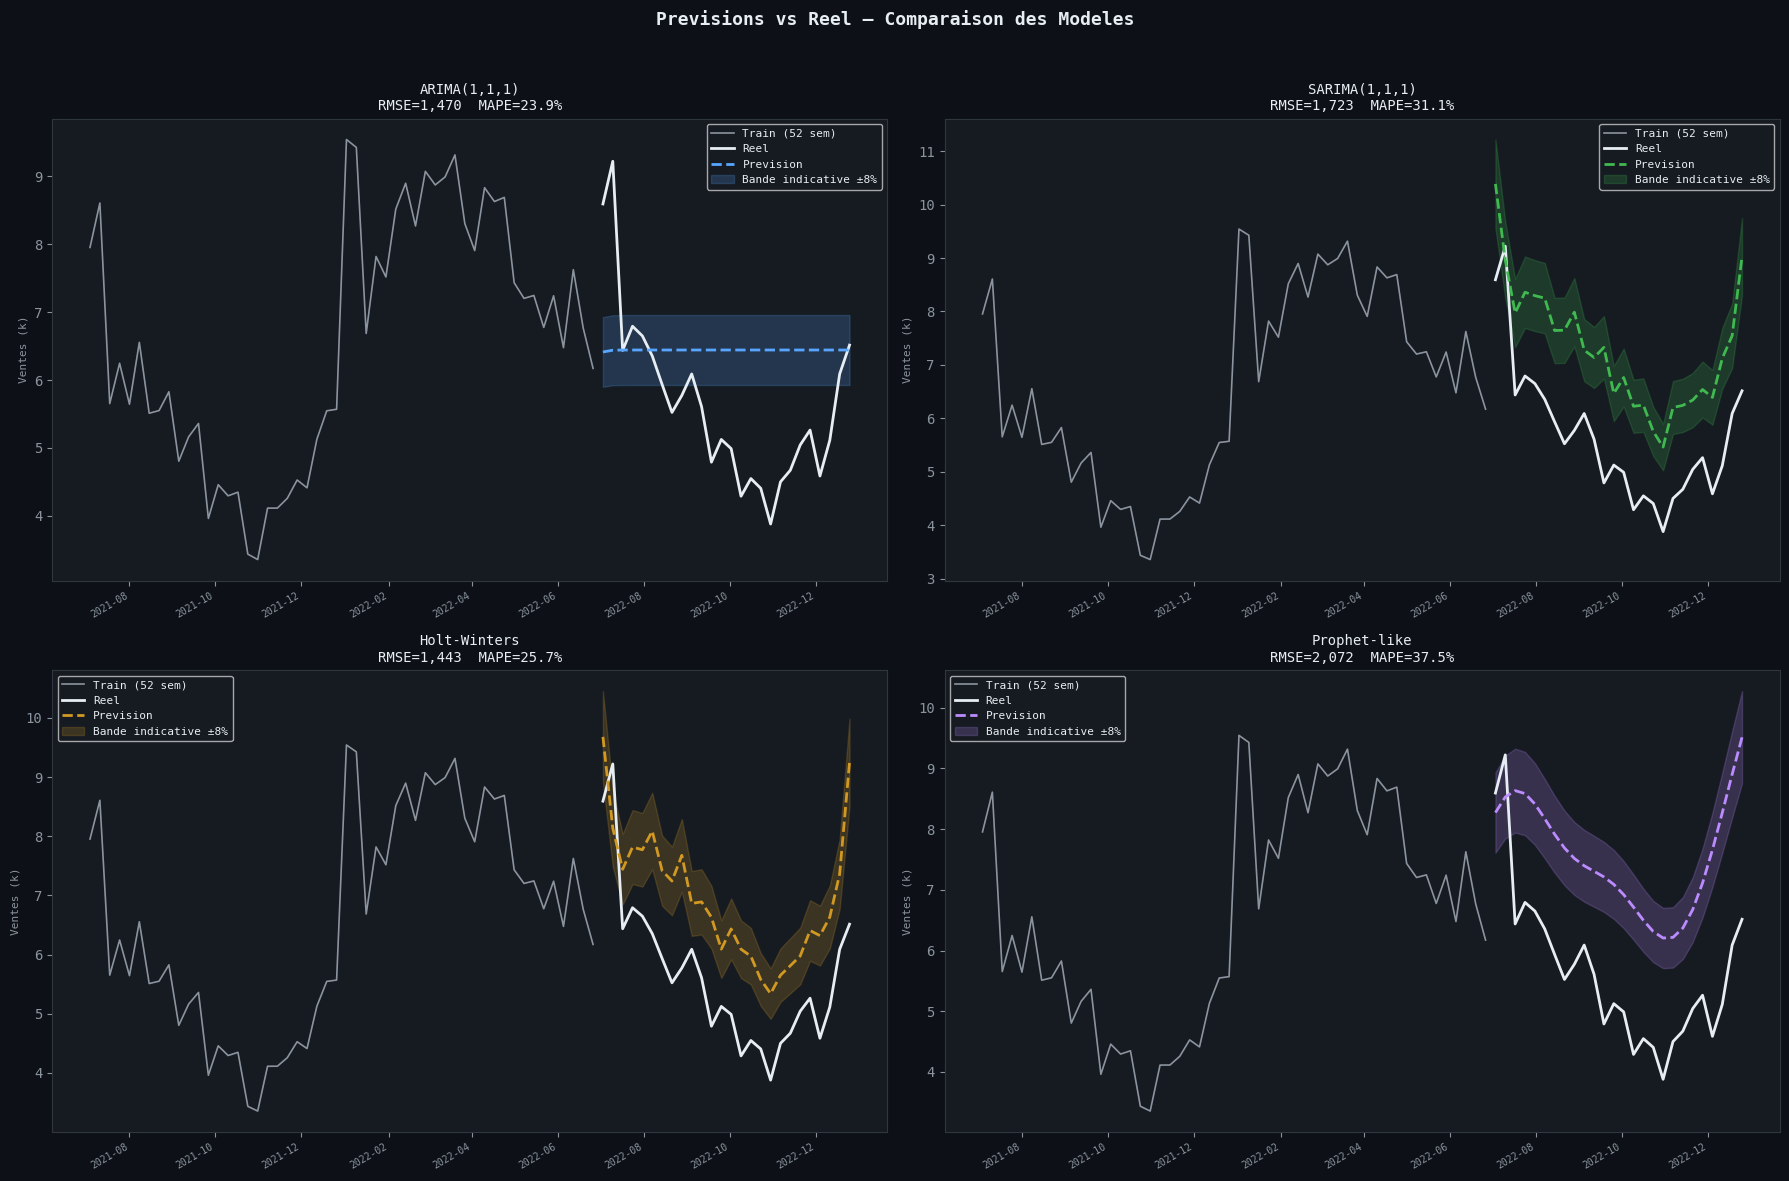

Comparaison sauvegardee


In [16]:

# Palette de couleurs
DARK = "#0d1117"
CARD = "#161b22"
BORD = "#30363d"
TEXT = "#e6edf3"
DIM = "#8b949e"
BLUE = "#58a6ff"
GREEN = "#3fb950"
ORNG = "#d29922"
RED = "#f85149"
PURP = "#bc8cff"

# Comparaison des modèles
modeles = {
    "ARIMA(1,1,1)": (fc_arima, rmse_arima, mae_arima, mape_arima),
    "SARIMA(1,1,1)": (fc_sarima, rmse_sarima, mae_sarima, mape_sarima),
    "Holt-Winters": (fc_hw, rmse_hw, mae_hw, mape_hw),
    "Prophet-like": (fc_prophet, rmse_prophet, mae_prophet, mape_prophet),
}

comp_df = pd.DataFrame([
    {
        "Modele": k,
        "RMSE": v[1],
        "MAE": v[2],
        "MAPE(%)": round(v[3], 2)
    }
    for k, v in modeles.items()
]).sort_values("RMSE")

print("=== COMPARAISON MODELES ===")
print(comp_df.to_string(index=False))

best_model = comp_df.iloc[0]["Modele"]
print(f"\nMeilleur modele (RMSE) : {best_model}")

# Graphiques de comparaison
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.patch.set_facecolor(DARK)

fig.suptitle(
    "Previsions vs Reel — Comparaison des Modeles",
    color=TEXT,
    fontsize=13,
    fontweight="bold"
)

colors_m = [BLUE, GREEN, ORNG, PURP]

for (name, (fc, rmse, mae, mape)), ax, clr in zip(
    modeles.items(), axes.flat, colors_m
):
    ax.set_facecolor(CARD)

    ax.plot(
        train_ts.iloc[-52:].index,
        train_ts.iloc[-52:] / 1000,
        color=DIM,
        linewidth=1.2,
        label="Train (52 sem)"
    )

    ax.plot(
        test_ts.index,
        test_ts / 1000,
        color=TEXT,
        linewidth=2,
        label="Reel"
    )

    ax.plot(
        fc.index,
        fc / 1000,
        color=clr,
        linewidth=2,
        linestyle="--",
        label="Prevision"
    )

    ax.fill_between(
        fc.index,
        fc / 1000 * 0.92,
        fc / 1000 * 1.08,
        alpha=0.2,
        color=clr,
        label="Bande indicative ±8%"
    )

    # CORRECTION : appel complet à ax.set_title()
    ax.set_title(
        f"{name}\nRMSE={rmse:,.0f}  MAPE={mape:.1f}%",
        color=TEXT,
        fontsize=10
    )

    ax.set_ylabel("Ventes (k)", color=DIM, fontsize=8)
    ax.legend(fontsize=8, labelcolor=TEXT, facecolor=CARD)

    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))

    plt.setp(
        ax.xaxis.get_majorticklabels(),
        rotation=30,
        ha="right",
        fontsize=7
    )

    for s in ax.spines.values():
        s.set_color(BORD)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "../images/04_forecasts_comparison.png",
    dpi=120,
    bbox_inches="tight",
    facecolor=DARK
)

plt.show()
print("Comparaison sauvegardee")


## 11. Dashboard Final

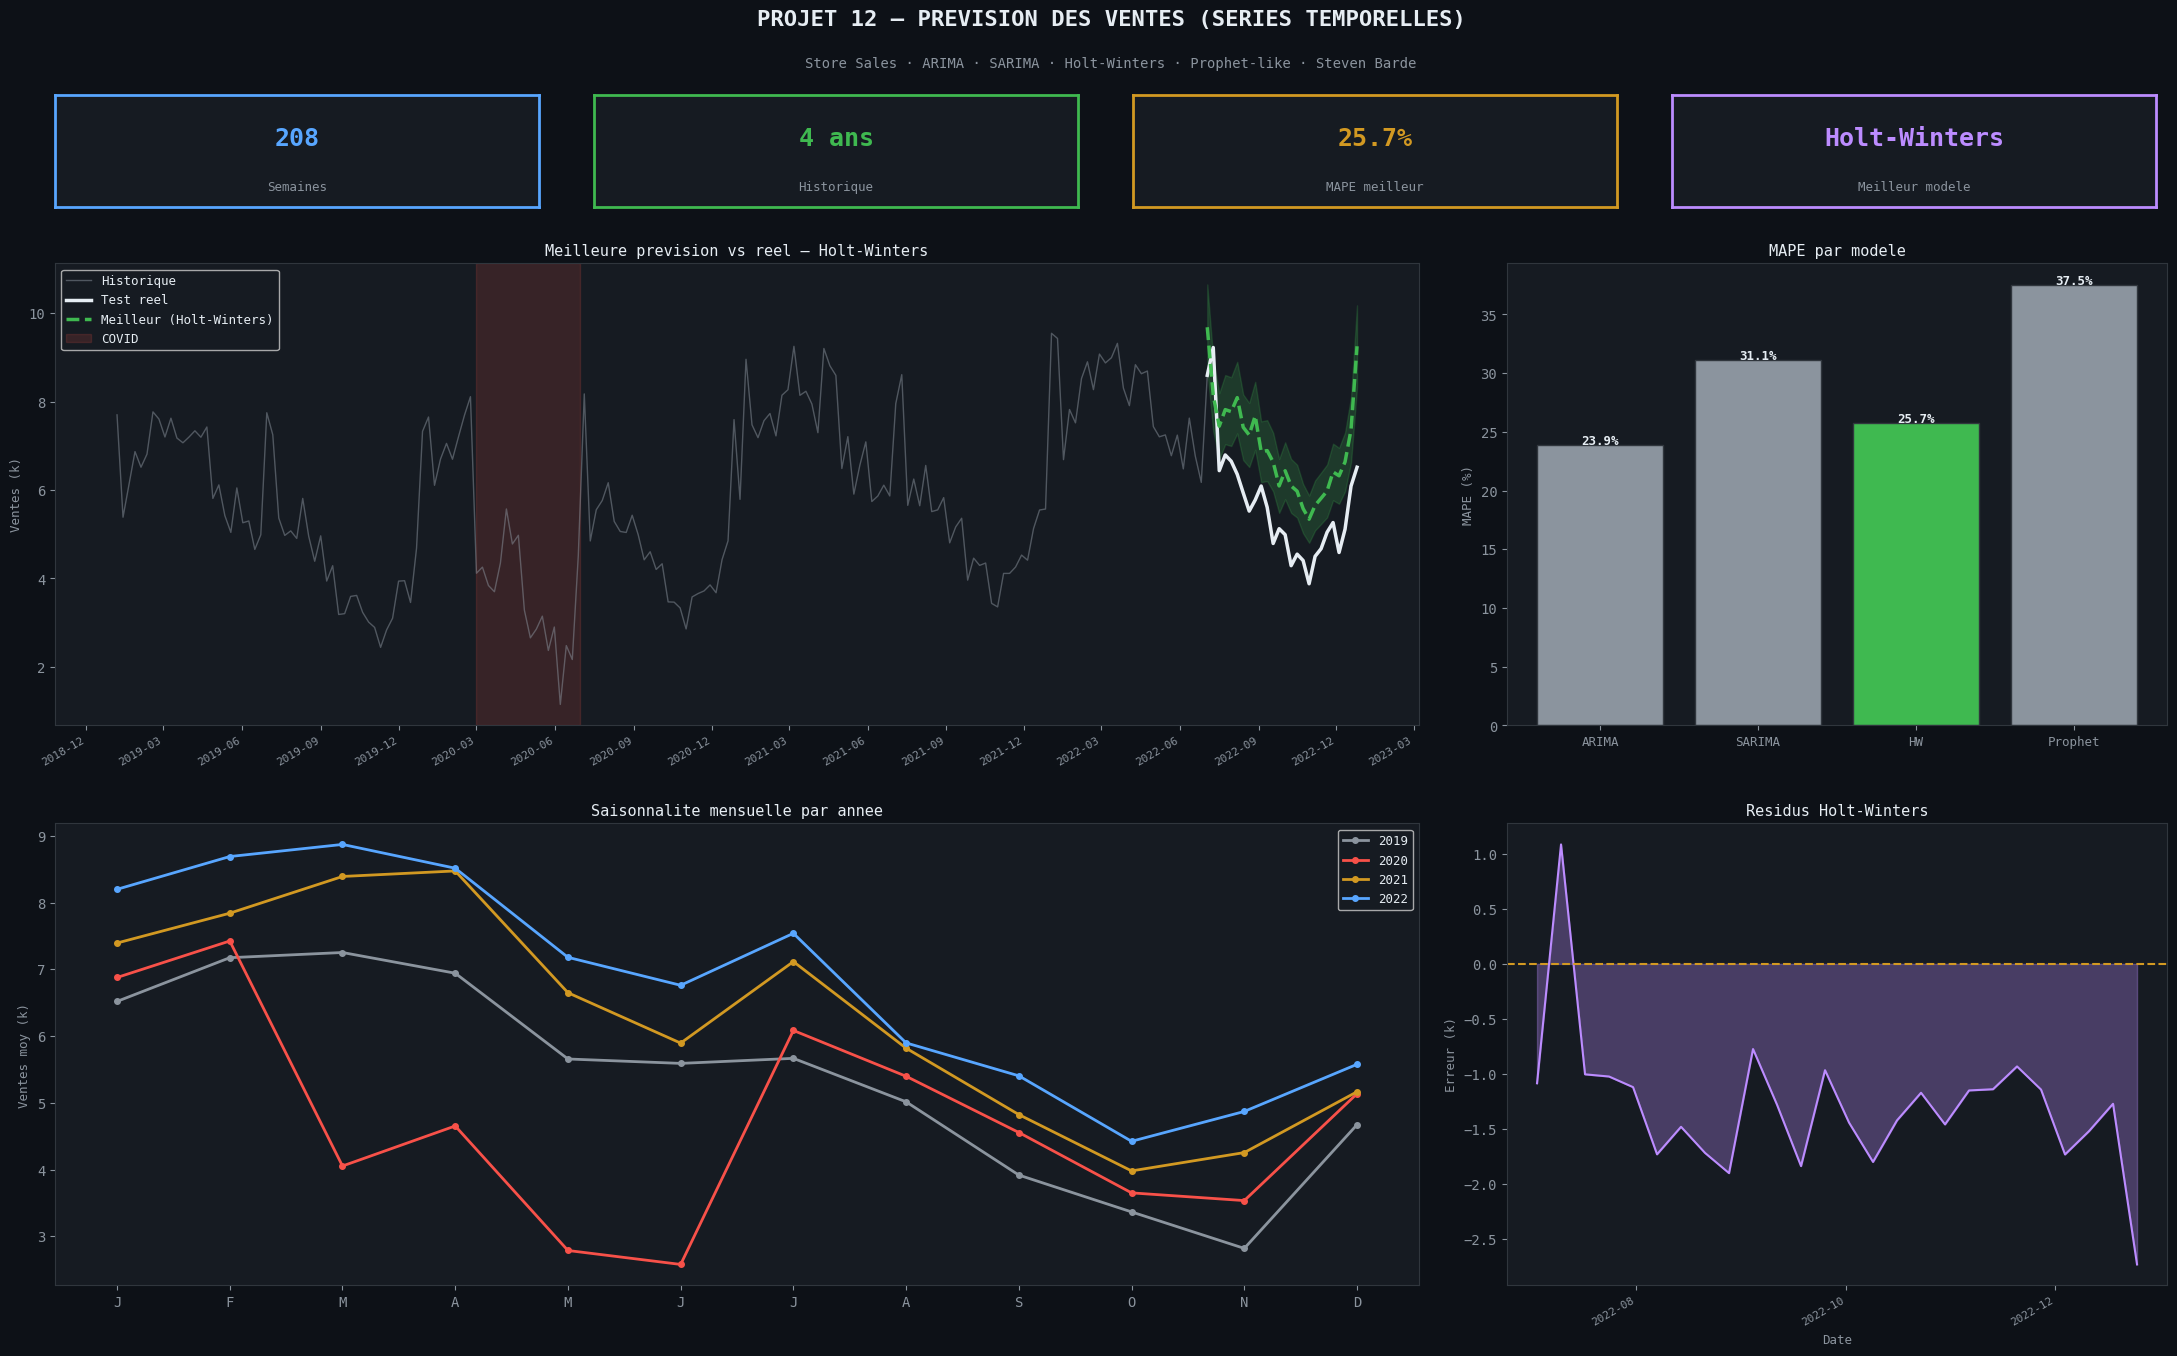

Dashboard projet 12 sauvegarde


In [17]:
DARK="#0d1117"; CARD="#161b22"; BORD="#30363d"; TEXT="#e6edf3"
DIM="#8b949e"; BLUE="#58a6ff"; GREEN="#3fb950"; ORNG="#d29922"; RED="#f85149"; PURP="#bc8cff"

best_fc, best_rmse, best_mae, best_mape = modeles[best_model]

fig = plt.figure(figsize=(22, 14))
fig.patch.set_facecolor(DARK)
fig.text(0.5,0.97,"PROJET 12 — PREVISION DES VENTES (SERIES TEMPORELLES)",
         ha="center",color=TEXT,fontsize=16,fontweight="bold")
fig.text(0.5,0.94,"Store Sales · ARIMA · SARIMA · Holt-Winters · Prophet-like · Steven Barde",
         ha="center",color=DIM,fontsize=10)

kpis = [(f"{len(ts)}","Semaines",BLUE),("4 ans","Historique",GREEN),
        (f"{best_mape:.1f}%","MAPE meilleur",ORNG),(best_model,"Meilleur modele",PURP)]
for i,(val,lbl,clr) in enumerate(kpis):
    ak = fig.add_axes([0.02+i*0.245,0.84,0.22,0.08])
    ak.set_facecolor(CARD)
    for s in ak.spines.values(): s.set_color(clr); s.set_linewidth(2)
    ak.set_xticks([]); ak.set_yticks([])
    ak.text(0.5,0.62,val,ha="center",va="center",color=clr,fontsize=18,fontweight="bold",transform=ak.transAxes)
    ak.text(0.5,0.18,lbl,ha="center",va="center",color=DIM,fontsize=9,transform=ak.transAxes)

ax1 = fig.add_axes([0.02,0.47,0.62,0.33]); ax1.set_facecolor(CARD)
ax1.plot(ts.index, ts/1000, color=DIM, linewidth=1, alpha=0.5, label="Historique")
ax1.plot(test_ts.index, test_ts/1000, color=TEXT, linewidth=2.5, label="Test reel")
ax1.plot(best_fc.index, best_fc/1000, color=GREEN, linewidth=2.5, linestyle="--", label=f"Meilleur ({best_model})")
ax1.fill_between(best_fc.index, best_fc/1000*0.90, best_fc/1000*1.10, alpha=0.2, color=GREEN)
ax1.axvspan(pd.Timestamp("2020-03-01"),pd.Timestamp("2020-06-30"),alpha=0.15,color=RED,label="COVID")
ax1.set_title(f"Meilleure prevision vs reel — {best_model}",color=TEXT,fontsize=11)
ax1.set_ylabel("Ventes (k)",color=DIM,fontsize=9)
ax1.legend(fontsize=9,labelcolor=TEXT,facecolor=CARD)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax1.xaxis.get_majorticklabels(),rotation=30,ha="right",fontsize=8)
for s in ax1.spines.values(): s.set_color(BORD)

ax2 = fig.add_axes([0.68,0.47,0.30,0.33]); ax2.set_facecolor(CARD)
mnames = list(modeles.keys())
mapes  = [modeles[m][3] for m in mnames]
clrs2  = [GREEN if m==best_model else DIM for m in mnames]
bars2  = ax2.bar(range(len(mnames)), mapes, color=clrs2, edgecolor=BORD)
for bar, v in zip(bars2, mapes):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05, f"{v:.1f}%",
             ha="center",color=TEXT,fontsize=9,fontweight="bold")
ax2.set_xticks(range(len(mnames)))
ax2.set_xticklabels(["ARIMA","SARIMA","HW","Prophet"],color=DIM,fontsize=9)
ax2.set_title("MAPE par modele",color=TEXT,fontsize=11)
ax2.set_ylabel("MAPE (%)",color=DIM,fontsize=9)
for s in ax2.spines.values(): s.set_color(BORD)

ax3 = fig.add_axes([0.02,0.07,0.62,0.33]); ax3.set_facecolor(CARD)
monthly_avg = df.groupby(["year","month"])["sales"].mean().reset_index()
for yr, clr in zip(sorted(df["year"].unique()), [DIM,RED,ORNG,BLUE]):
    row = monthly_avg[monthly_avg["year"]==yr]
    ax3.plot(row["month"], row["sales"]/1000, color=clr, linewidth=2, marker="o", markersize=4, label=str(yr))
month_names = ["J","F","M","A","M","J","J","A","S","O","N","D"]
ax3.set_xticks(range(1,13)); ax3.set_xticklabels(month_names,color=DIM)
ax3.set_title("Saisonnalite mensuelle par annee",color=TEXT,fontsize=11)
ax3.set_ylabel("Ventes moy (k)",color=DIM,fontsize=9)
ax3.legend(fontsize=9,labelcolor=TEXT,facecolor=CARD)
for s in ax3.spines.values(): s.set_color(BORD)

ax4 = fig.add_axes([0.68,0.07,0.30,0.33]); ax4.set_facecolor(CARD)
res_best = (test_ts - best_fc).values
ax4.plot(test_ts.index, res_best/1000, color=PURP, linewidth=1.5)
ax4.fill_between(test_ts.index, res_best/1000, alpha=0.3, color=PURP)
ax4.axhline(0, color=ORNG, linewidth=1.5, linestyle="--")
ax4.set_title(f"Residus {best_model}",color=TEXT,fontsize=11)
ax4.set_xlabel("Date",color=DIM,fontsize=9); ax4.set_ylabel("Erreur (k)",color=DIM,fontsize=9)
ax4.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax4.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.setp(ax4.xaxis.get_majorticklabels(),rotation=30,ha="right",fontsize=8)
for s in ax4.spines.values(): s.set_color(BORD)

plt.savefig("../images/00_dashboard_timeseries.png",dpi=130,bbox_inches="tight",facecolor=DARK)
plt.show(); print("Dashboard projet 12 sauvegarde")

In [18]:
print("=" * 55)
print("    SYNTHESE — PROJET 12 SERIES TEMPORELLES")
print("=" * 55)
print(f"Dataset : Store Sales ({len(ts)} semaines, 2019-2022)")
print(f"Horizon : {test_size} semaines")
print()
for k, (_, rmse, mae, mape) in modeles.items():
    print(f"  {k:20s} | RMSE={rmse:>8,.0f}  MAPE={mape:.1f}%")
print(f"Meilleur : {best_model}  (MAPE={best_mape:.1f}%)")
print("Tendance : croissante +8 unites/semaine")
print("Saisonnalite : pic ete (Jul) et fin annee (Dec)")
print("Anomalie : Choc COVID Q1-Q2 2020")
print("=" * 55)

    SYNTHESE — PROJET 12 SERIES TEMPORELLES
Dataset : Store Sales (208 semaines, 2019-2022)
Horizon : 26 semaines

  ARIMA(1,1,1)         | RMSE=   1,470  MAPE=23.9%
  SARIMA(1,1,1)        | RMSE=   1,723  MAPE=31.1%
  Holt-Winters         | RMSE=   1,443  MAPE=25.7%
  Prophet-like         | RMSE=   2,072  MAPE=37.5%
Meilleur : Holt-Winters  (MAPE=25.7%)
Tendance : croissante +8 unites/semaine
Saisonnalite : pic ete (Jul) et fin annee (Dec)
Anomalie : Choc COVID Q1-Q2 2020
